# Loan Approval Prediction

**The goal:** Predict whether a loan application will be approved or rejected.

---

## Attribute Information

1- **loan_id:** unique ID for each loan application.

2- **no_of_dependents:** number of dependents of the applicant.

3- **education:** education level of the applicant.  
   [Graduate, Not Graduate]

4- **self_employed:** whether the applicant is self-employed or not.  
   [Yes, No]

5- **income_annum:** annual income of the applicant.

6- **loan_amount:** total loan amount requested by the applicant.

7- **loan_term:** duration of the loan in years.

8- **cibil_score:** credit score of the applicant.

9- **residential_assets_value:** value of residential assets owned by the applicant.

10- **commercial_assets_value:** value of commercial assets owned by the applicant.

11- **luxury_assets_value:** value of luxury assets owned by the applicant.

12- **bank_asset_value:** value of bank assets owned by the applicant.

13- **loan_status:** output class.  
   [Approved, Rejected]

---

## Name of Students & ID:

Jood Sari AlOtaibi  - 446000792

khulood Alkhuzaee - 446000432

Rehaf Dahlawi - 446000992  

---


# 1- Dataset Understanding

Understand and describe the dataset.

In [ ]:
# importing the libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
# loading the dataset file

loan_df = pd.read_csv('/content/loan_approval_dataset.csv')

In [ ]:
# displaying the first rows from the dataset

loan_df.head(10)

,loan_id,no_of_dependents,education,self_employed,income_annum,loan_amount,loan_term,cibil_score,residential_assets_value,commercial_assets_value,luxury_assets_value,bank_asset_value,loan_status
0,1,2,Graduate,No,9600000,29900000,12,778,2400000,17600000,22700000,8000000,Approved
1,2,0,Not Graduate,Yes,4100000,12200000,8,417,2700000,2200000,8800000,3300000,Rejected
2,3,3,Graduate,No,9100000,29700000,20,506,7100000,4500000,33300000,12800000,Rejected
3,4,3,Graduate,No,8200000,30700000,8,467,18200000,3300000,23300000,7900000,Rejected
4,5,5,Not Graduate,Yes,9800000,24200000,20,382,12400000,8200000,29400000,5000000,Rejected
5,6,0,Graduate,Yes,4800000,13500000,10,319,6800000,8300000,13700000,5100000,Rejected
6,7,5,Graduate,No,8700000,33000000,4,678,22500000,14800000,29200000,4300000,Approved
7,8,2,Graduate,Yes,5700000,15000000,20,382,13200000,5700000,11800000,6000000,Rejected
8,9,0,Graduate,Yes,800000,2200000,20,782,1300000,800000,2800000,600000,Approved
9,10,5,Not Graduate,No,1100000,4300000,10,388,3200000,1400000,3300000,1600000,Rejected


In [ ]:
# checking the size of the dataset

loan_df.shape

(4269, 13)

In [ ]:
# showing all column names

loan_df.columns

Index(['loan_id', ' no_of_dependents', ' education', ' self_employed',
       ' income_annum', ' loan_amount', ' loan_term', ' cibil_score',
       ' residential_assets_value', ' commercial_assets_value',
       ' luxury_assets_value', ' bank_asset_value', ' loan_status'],
      dtype='object')

In [ ]:
# getting information about data types and null values

loan_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4269 entries, 0 to 4268
Data columns (total 13 columns):
 #   Column                     Non-Null Count  Dtype 
---  ------                     --------------  ----- 
 0   loan_id                    4269 non-null   int64 
 1    no_of_dependents          4269 non-null   int64 
 2    education                 4269 non-null   object
 3    self_employed             4269 non-null   object
 4    income_annum              4269 non-null   int64 
 5    loan_amount               4269 non-null   int64 
 6    loan_term                 4269 non-null   int64 
 7    cibil_score               4269 non-null   int64 
 8    residential_assets_value  4269 non-null   int64 
 9    commercial_assets_value   4269 non-null   int64 
 10   luxury_assets_value       4269 non-null   int64 
 11   bank_asset_value          4269 non-null   int64 
 12   loan_status               4269 non-null   object
dtypes: int64(10), object(3)
memory usage: 433.7+ KB


In [ ]:
# showing statistics for numerical columns

loan_df.describe()

,loan_id,no_of_dependents,income_annum,loan_amount,loan_term,cibil_score,residential_assets_value,commercial_assets_value,luxury_assets_value,bank_asset_value
count,4269.000000,4269.000000,4.269000e+03,4.269000e+03,4269.000000,4269.000000,4.269000e+03,4.269000e+03,4.269000e+03,4.269000e+03
mean,2135.000000,2.498712,5.059124e+06,1.513345e+07,10.900445,599.936051,7.472617e+06,4.973155e+06,1.512631e+07,4.976692e+06
std,1232.498479,1.695910,2.806840e+06,9.043363e+06,5.709187,172.430401,6.503637e+06,4.388966e+06,9.103754e+06,3.250185e+06
min,1.000000,0.000000,2.000000e+05,3.000000e+05,2.000000,300.000000,-1.000000e+05,0.000000e+00,3.000000e+05,0.000000e+00
25%,1068.000000,1.000000,2.700000e+06,7.700000e+06,6.000000,453.000000,2.200000e+06,1.300000e+06,7.500000e+06,2.300000e+06
50%,2135.000000,3.000000,5.100000e+06,1.450000e+07,10.000000,600.000000,5.600000e+06,3.700000e+06,1.460000e+07,4.600000e+06
75%,3202.000000,4.000000,7.500000e+06,2.150000e+07,16.000000,748.000000,1.130000e+07,7.600000e+06,2.170000e+07,7.100000e+06
max,4269.000000,5.000000,9.900000e+06,3.950000e+07,20.000000,900.000000,2.910000e+07,1.940000e+07,3.920000e+07,1.470000e+07


### Checking Missing Values

In this step, we check whether the dataset contains any missing or null values.

In [ ]:
# checking if there are missing values in the dataset

loan_df.isnull().sum()

,0
loan_id,0
no_of_dependents,0
education,0
self_employed,0
income_annum,0
loan_amount,0
loan_term,0
cibil_score,0
residential_assets_value,0
commercial_assets_value,0


The dataset does not contain any missing values, which means the data is clean and suitable for machine learning preprocessing and analysis.

### Target Variable Distribution

Here, we analyze the distribution of the target variable (loan_status) to understand the balance between approved and rejected loans.

In [ ]:
# checking how many approved and rejected loans exist

counts = loan_df[' loan_status'].value_counts()

print(counts)

 loan_status
Approved    2656
Rejected    1613
Name: count, dtype: int64


The distribution of the target variable shows the number of approved and rejected loan applications in the dataset.
This helps us understand whether the dataset is balanced or not before building machine learning models.

# 2- Data Preprocessing
In this section, we prepare the dataset for machine learning by encoding categorical features, checking data quality, visualizing important patterns, scaling numerical features, and splitting the dataset into training and testing sets.

# 2A) Encoding Categorical Features
Categorical columns were converted into numerical values using Label Encoding because machine learning models cannot process text values directly.

In [ ]:
# importing LabelEncoder
from sklearn.preprocessing import LabelEncoder

# creating encoder object
le = LabelEncoder()

# encoding categorical columns
loan_df[' education'] = le.fit_transform(loan_df[' education'])
loan_df[' self_employed'] = le.fit_transform(loan_df[' self_employed'])
loan_df[' loan_status'] = le.fit_transform(loan_df[' loan_status'])

# displaying first rows after encoding
loan_df.head()

,loan_id,no_of_dependents,education,self_employed,income_annum,loan_amount,loan_term,cibil_score,residential_assets_value,commercial_assets_value,luxury_assets_value,bank_asset_value,loan_status
0,1,2,0,0,9600000,29900000,12,778,2400000,17600000,22700000,8000000,0
1,2,0,1,1,4100000,12200000,8,417,2700000,2200000,8800000,3300000,1
2,3,3,0,0,9100000,29700000,20,506,7100000,4500000,33300000,12800000,1
3,4,3,0,0,8200000,30700000,8,467,18200000,3300000,23300000,7900000,1
4,5,5,1,1,9800000,24200000,20,382,12400000,8200000,29400000,5000000,1


# 2B) Checking Missing Values
The dataset was checked for missing values to ensure data quality before training machine learning models.

In [ ]:
# checking if there are missing values in the dataset
loan_df.isnull().sum()

,0
loan_id,0
no_of_dependents,0
education,0
self_employed,0
income_annum,0
loan_amount,0
loan_term,0
cibil_score,0
residential_assets_value,0
commercial_assets_value,0


# 2C) Checking Duplicate Values
Duplicate rows were checked to avoid repeated information that may negatively affect model performance.

In [ ]:
# checking duplicate rows
Duplicates = loan_df.duplicated().sum()
print("Number of duplicate rows:" , Duplicates)

Number of duplicate rows: 0


# 2D) Data Visualization
Visualization helps in understanding data distribution, detecting patterns, and identifying important features before building machine learning models.

## Loan Status Distribution

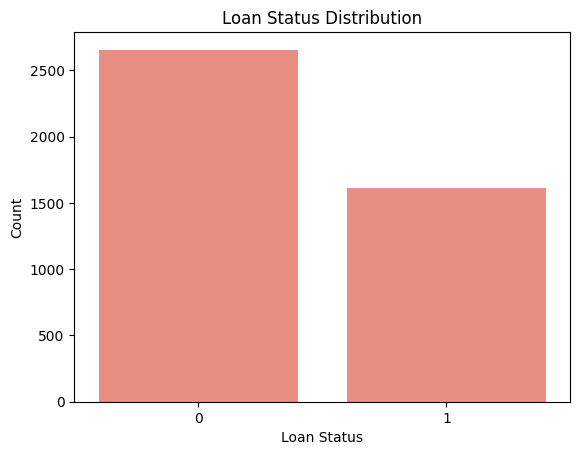

In [ ]:
# visualizing approved and rejected loans

sns.countplot(x=' loan_status', data=loan_df, color='salmon')

plt.title('Loan Status Distribution')
plt.xlabel('Loan Status')
plt.ylabel('Count')

plt.show()

The visualization shows that approved loans are more common than rejected loans in the dataset.

## Education Distribution

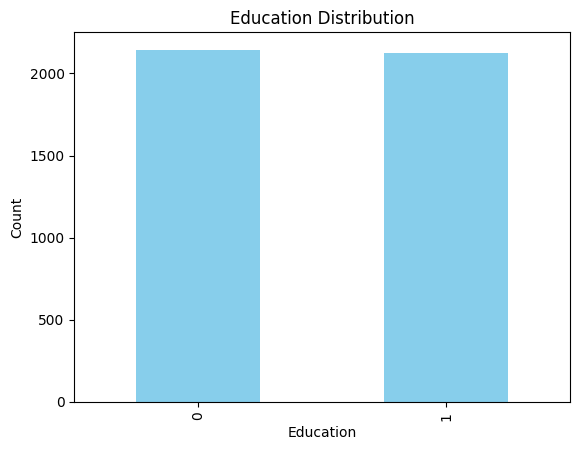

In [ ]:
# visualizing education categories

loan_df[' education'].value_counts().plot(kind='bar', color='skyblue')

plt.title('Education Distribution')
plt.xlabel('Education')
plt.ylabel('Count')

plt.show()

The dataset contains both graduate and non-graduate applicants with similar distribution.

## CIBIL Score Distribution

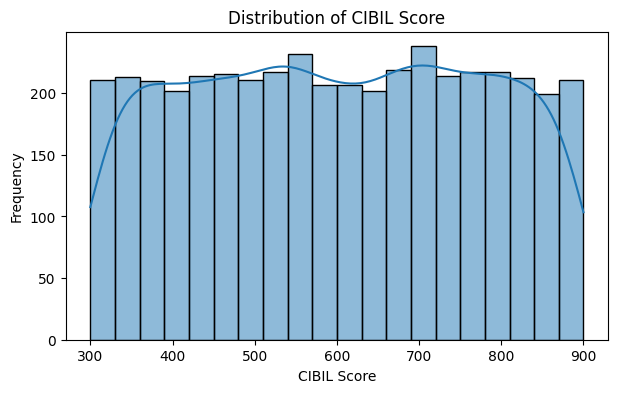

In [ ]:
# distribution of CIBIL score

plt.figure(figsize=(7,4))

sns.histplot(loan_df[' cibil_score'], kde=True, bins=20)

plt.title('Distribution of CIBIL Score')
plt.xlabel('CIBIL Score')
plt.ylabel('Frequency')

plt.show()

Most applicants have CIBIL scores distributed between 300 and 900.

## Annual Income Boxplot

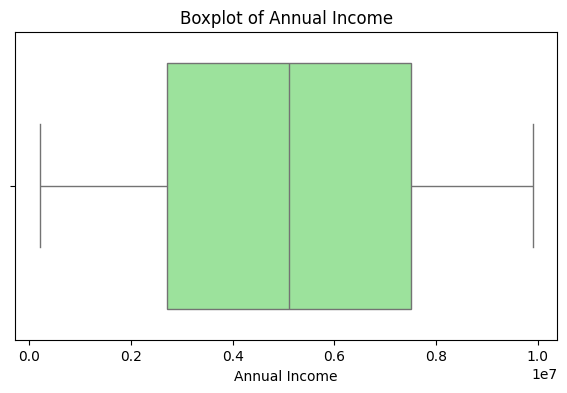

In [ ]:
# boxplot for annual income

plt.figure(figsize=(7,4))

sns.boxplot(x=loan_df[' income_annum'], color='lightgreen')

plt.title('Boxplot of Annual Income')
plt.xlabel('Annual Income')

plt.show()

The annual income feature contains a wide range of values with some variations across applicants.

# 2E) Feature Scaling
Feature scaling was applied using StandardScaler to normalize numerical values and improve machine learning model performance.

In [ ]:
# importing StandardScaler
from sklearn.preprocessing import StandardScaler

# creating scaler object
scaler = StandardScaler()

# selecting numerical columns
num_cols = [
    ' income_annum',
    ' loan_amount',
    ' cibil_score',
    ' residential_assets_value',
    ' commercial_assets_value',
    ' luxury_assets_value',
    ' bank_asset_value'
]

# applying scaling
loan_df[num_cols] = scaler.fit_transform(loan_df[num_cols])

# displaying first rows
loan_df.head()

,loan_id,no_of_dependents,education,self_employed,income_annum,loan_amount,loan_term,cibil_score,residential_assets_value,commercial_assets_value,luxury_assets_value,bank_asset_value,loan_status
0,1,2,0,0,1.617979,1.633052,12,1.032792,-0.780058,2.877289,0.832028,0.930304,0
1,2,0,1,1,-0.341750,-0.324414,8,-1.061051,-0.733924,-0.631921,-0.694993,-0.515936,1
2,3,3,0,0,1.439822,1.610933,20,-0.544840,-0.057300,-0.107818,1.996520,2.407316,1
3,4,3,0,0,1.119139,1.721525,8,-0.771045,1.649637,-0.381263,0.897943,0.899533,1
4,5,5,1,1,1.689242,1.002681,20,-1.264055,0.757724,0.735304,1.568075,0.007172,1


# 2F) Feature & Target Split
The dataset was divided into features (X) and target variable (y) for machine learning training.

In [ ]:
# defining features and target variable

X = loan_df.drop(' loan_status', axis=1)

y = loan_df[' loan_status']

# 2G) Train/Test Split
The dataset was divided into training and testing sets. The training set is used to train the model, while the testing set is used to evaluate its performance.

In [ ]:
# splitting dataset into training and testing sets

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

# displaying shapes
print(X_train.shape)
print(X_test.shape)

(3415, 12)
(854, 12)


# 3- Model Implementation
In this section, machine learning models were implemented to predict loan approval decisions based on customer financial information.

## 3A) Feature Selection
Important features related to loan approval were selected for model training.

In [ ]:
# selecting important features for model training

col = [
    ' income_annum',
    ' loan_amount',
    ' cibil_score',
    ' education',
    ' self_employed'
]

# creating a new dataframe with selected features

df_selected = loan_df[col].copy()

# displaying first rows

df_selected.head()

,income_annum,loan_amount,cibil_score,education,self_employed
0,1.617979,1.633052,1.032792,0,0
1,-0.341750,-0.324414,-1.061051,1,1
2,1.439822,1.610933,-0.544840,0,0
3,1.119139,1.721525,-0.771045,0,0
4,1.689242,1.002681,-1.264055,1,1


## 3B) Defining Features and Target Variable
Features (X) and target variable (y) were defined before training the machine learning models.

In [ ]:
# defining features and target variable

X = loan_df[col]

y = loan_df[' loan_status']

# checking shapes

print("Shape of X:", X.shape)
print("Shape of y:", y.shape)

Shape of X: (4269, 5)
Shape of y: (4269,)


## 3C) Train / Validation Split
The dataset was divided into training and validation sets to evaluate model performance.

In [ ]:
# splitting data into training and validation sets

from sklearn.model_selection import train_test_split

X_train_final, X_valid, y_train_final, y_valid = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training size:", X_train_final.shape)
print("Validation size:", X_valid.shape)

Training size: (3415, 5)
Validation size: (854, 5)


## 3D) Random Forest Model
Random Forest Classifier was implemented to predict loan approval decisions.

In [ ]:
# importing Random Forest model and accuracy score

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

# creating Random Forest model

rf_model = RandomForestClassifier(random_state=42)

# training the model

rf_model.fit(X_train_final, y_train_final)

# making predictions

y_pred_rf = rf_model.predict(X_valid)

# calculating accuracy

rf_accuracy = accuracy_score(y_valid, y_pred_rf)

print(f"Random Forest Accuracy: {rf_accuracy * 100:.2f}%")

Random Forest Accuracy: 95.78%


## 3E) Feature Importance
Feature importance was analyzed to identify the most influential variables affecting loan approval decisions.

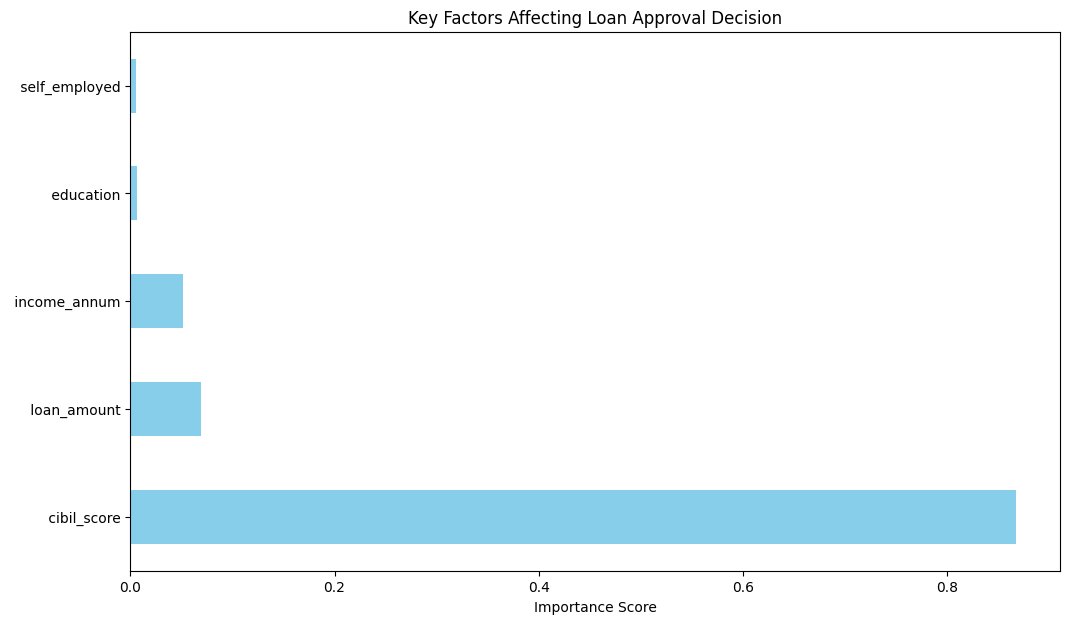

In [ ]:
# plotting feature importance

import matplotlib.pyplot as plt
import pandas as pd

plt.figure(figsize=(12,7))

feat_importances = pd.Series(
    rf_model.feature_importances_,
    index=X.columns
)

feat_importances.nlargest(5).plot(kind='barh', color='skyblue')

plt.title('Key Factors Affecting Loan Approval Decision')
plt.xlabel('Importance Score')

plt.show()

CIBIL score is expected to be one of the most important features affecting loan approval decisions because it represents the applicant's creditworthiness.

## 3F) Decision Tree Model
Decision Tree Classifier was implemented and compared with Random Forest performance.

In [ ]:
# importing Decision Tree model

from sklearn.tree import DecisionTreeClassifier

# creating Decision Tree model

dt_model = DecisionTreeClassifier(random_state=42)

# training the model

dt_model.fit(X_train_final, y_train_final)

# making predictions

y_pred_dt = dt_model.predict(X_valid)

# calculating accuracy

dt_accuracy = accuracy_score(y_valid, y_pred_dt)

print(f"Random Forest Accuracy: {rf_accuracy * 100:.2f}%")
print(f"Decision Tree Accuracy: {dt_accuracy * 100:.2f}%")

Random Forest Accuracy: 95.78%
Decision Tree Accuracy: 92.97%


These results give an initial comparison between Random Forest and Decision Tree models.

# 4- Evaluation & Comparison
In this section, the machine learning models are evaluated and compared using accuracy, confusion matrix, and classification report.

## 4A) Confusion Matrix
Confusion Matrix is used to show the number of correct and incorrect predictions made by the model.



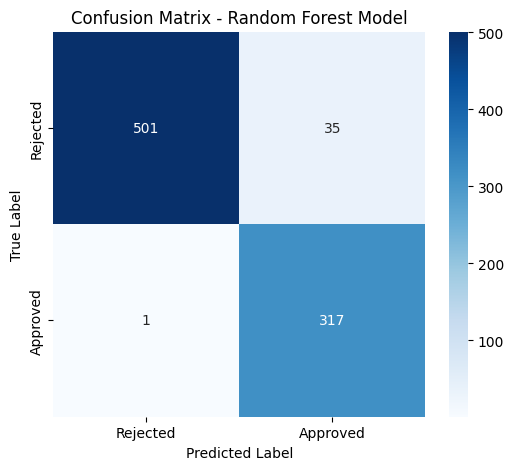

In [ ]:
# importing confusion matrix

from sklearn.metrics import confusion_matrix

# creating confusion matrix for Random Forest

cm = confusion_matrix(y_valid, y_pred_rf)

# visualizing confusion matrix

plt.figure(figsize=(6,5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Rejected', 'Approved'],
    yticklabels=['Rejected', 'Approved']
)

plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix - Random Forest Model')

plt.show()

## 4B) Classification Report
Classification Report shows precision, recall, F1-score, and accuracy for the model.

In [ ]:
# importing classification report

from sklearn.metrics import classification_report

# printing classification report for Random Forest

print("Classification Report for Random Forest:")
print(classification_report(y_valid, y_pred_rf))

Classification Report for Random Forest:
              precision    recall  f1-score   support

           0       1.00      0.93      0.97       536
           1       0.90      1.00      0.95       318

    accuracy                           0.96       854
   macro avg       0.95      0.97      0.96       854
weighted avg       0.96      0.96      0.96       854



## 4C) Model Accuracy Comparison
The accuracy scores of Random Forest and Decision Tree models are compared to identify the better-performing model.

In [ ]:
# comparing model accuracies

print(f"Random Forest Accuracy: {rf_accuracy * 100:.2f}%")
print(f"Decision Tree Accuracy: {dt_accuracy * 100:.2f}%")

Random Forest Accuracy: 95.78%
Decision Tree Accuracy: 92.97%


Random Forest achieved better overall performance compared to Decision Tree and was selected as the final model.

# 5- Explanation

The Random Forest model achieved better performance compared to the Decision Tree model in predicting loan approval decisions.

The model showed high accuracy and produced reliable predictions on the validation dataset.

Feature importance analysis showed that CIBIL score was the most influential factor affecting loan approval decisions.

Loan amount and annual income also had noticeable impact on prediction results.

The Decision Tree model achieved good results, but its accuracy was lower than Random Forest, indicating that Random Forest generalized better on the dataset.

Overall, Random Forest was selected as the final model because it provided more stable and accurate predictions.